In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]
Python executable: C:\Users\vanga\OneDrive\Desktop\project me\BrainSight\venv\Scripts\python.exe


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from pathlib import Path

print("All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!


In [4]:
from pathlib import Path

dataset_path = Path("../dataset/brain_tumor_dataset")

print("Dataset exists:", dataset_path.exists())
print("Dataset location:", dataset_path.resolve())

Dataset exists: True
Dataset location: C:\Users\vanga\OneDrive\Desktop\project me\BrainSight\dataset\brain_tumor_dataset


In [5]:
files = sorted(dataset_path.glob("*.parquet"))

print("Number of Parquet files:", len(files))

for file in files:
    print(file.name)

Number of Parquet files: 4
test-00000-of-00001.parquet
train-00000-of-00003.parquet
train-00001-of-00003.parquet
train-00002-of-00003.parquet


In [6]:
import pyarrow.parquet as pq

for file in files:
    parquet_file = pq.ParquetFile(file)

    print(file.name, ":", parquet_file.metadata.num_rows, "records")

test-00000-of-00001.parquet : 542 records
train-00000-of-00003.parquet : 841 records
train-00001-of-00003.parquet : 841 records
train-00002-of-00003.parquet : 840 records


In [7]:
parquet_file = pq.ParquetFile(files[0])

print("Available columns:")
print(parquet_file.schema.names)

Available columns:
['id', 'pid', 'label_id', 'label_name', 'fold', 'bytes', 'path', 'bytes', 'path', 'element']


In [8]:
print(parquet_file.schema)

required group field_id=-1 schema {
  optional binary field_id=-1 id (String);
  optional binary field_id=-1 pid (String);
  optional int32 field_id=-1 label_id;
  optional binary field_id=-1 label_name (String);
  optional int32 field_id=-1 fold;
  optional group field_id=-1 image {
    optional binary field_id=-1 bytes;
    optional binary field_id=-1 path (String);
  }
  optional group field_id=-1 mask {
    optional binary field_id=-1 bytes;
    optional binary field_id=-1 path (String);
  }
  optional group field_id=-1 tumor_border (List) {
    repeated group field_id=-1 list {
      optional double field_id=-1 element;
    }
  }
}



In [9]:
sample = pq.read_table(
    files[0],
    columns=["id", "pid", "label_id", "label_name", "fold"]
).slice(0, 1)

print(sample.to_pandas().to_string(index=False))

id    pid  label_id label_name  fold
24 102420         1 meningioma     1


In [10]:
sample = pq.read_table(
    files[0],
    columns=["image"]
).slice(0, 1)

image_data = sample.to_pylist()[0]["image"]

print("Image data type:", type(image_data))
print("Image keys:", image_data.keys())
print("Image byte size:", len(image_data["bytes"]))
print("Image path:", image_data["path"])

Image data type: <class 'dict'>
Image keys: dict_keys(['bytes', 'path'])
Image byte size: 228274
Image path: None


In [11]:
from PIL import Image
from io import BytesIO

image = Image.open(BytesIO(image_data["bytes"]))

print("Image format:", image.format)
print("Image dimensions:", image.size)
print("Image mode:", image.mode)

Image format: PNG
Image dimensions: (512, 512)
Image mode: I;16


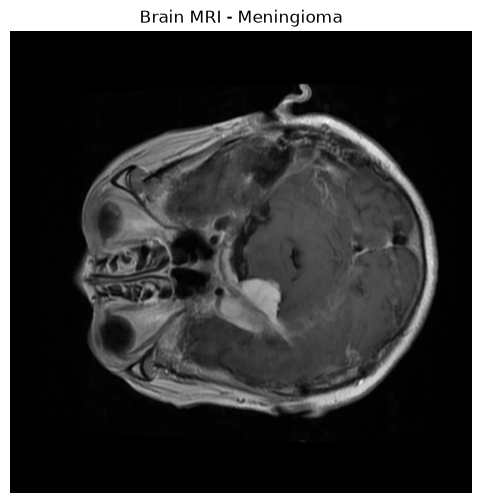

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.title("Brain MRI - Meningioma")
plt.axis("off")
plt.show()

In [13]:
import pandas as pd

metadata = pd.concat(
    [pd.read_parquet(file, columns=["id", "pid", "label_id", "label_name", "fold"])
     for file in files],
    ignore_index=True
)

class_counts = metadata["label_name"].value_counts()

print("Total images:", len(metadata))
print("\nImages per class:")
print(class_counts)

Total images: 3064

Images per class:
label_name
glioma        1426
pituitary      930
meningioma     708
Name: count, dtype: int64


In [14]:
print("Missing values in each column:")
print(metadata.isnull().sum())

print("\nUnique tumor classes:")
print(sorted(metadata["label_name"].unique()))

print("\nUnique label IDs:")
print(sorted(metadata["label_id"].unique()))

Missing values in each column:
id            0
pid           0
label_id      0
label_name    0
fold          0
dtype: int64

Unique tumor classes:
['glioma', 'meningioma', 'pituitary']

Unique label IDs:
[np.int32(1), np.int32(2), np.int32(3)]


In [15]:
# Count unique patients and images
total_patients = metadata["pid"].nunique()

images_per_patient = metadata.groupby("pid").size()

print("Total unique patients:", total_patients)
print("Average images per patient:", round(images_per_patient.mean(), 2))
print("Minimum images per patient:", images_per_patient.min())
print("Maximum images per patient:", images_per_patient.max())

print("\nImages per patient distribution:")
print(images_per_patient.describe())

Total unique patients: 233
Average images per patient: 13.15
Minimum images per patient: 1
Maximum images per patient: 38

Images per patient distribution:
count    233.000000
mean      13.150215
std        7.655779
min        1.000000
25%        7.000000
50%       13.000000
75%       18.000000
max       38.000000
dtype: float64


In [16]:
patients_per_class = (
    metadata.groupby("label_name")["pid"]
    .nunique()
    .sort_values(ascending=False)
)

print("Unique patients per tumor class:")
print(patients_per_class)

print("\nTotal unique patients:", metadata["pid"].nunique())

Unique patients per tumor class:
label_name
glioma        89
meningioma    82
pituitary     62
Name: pid, dtype: int64

Total unique patients: 233


In [17]:
patient_label_counts = metadata.groupby("pid")["label_name"].nunique()

multi_label_patients = patient_label_counts[
    patient_label_counts > 1
]

print("Patients associated with multiple tumor classes:",
      len(multi_label_patients))

if len(multi_label_patients) > 0:
    print("\nAffected patients:")
    print(multi_label_patients)
else:
    print("Every patient is associated with exactly one tumor class.")

Patients associated with multiple tumor classes: 0
Every patient is associated with exactly one tumor class.


In [18]:
patient_summary = (
    metadata.groupby("label_name")
    .agg(
        patients=("pid", "nunique"),
        images=("id", "count"),
        avg_images_per_patient=("pid", lambda x: x.value_counts().mean())
    )
    .sort_index()
)

print(patient_summary.round(2))

            patients  images  avg_images_per_patient
label_name                                          
glioma            89    1426                   16.02
meningioma        82     708                    8.63
pituitary         62     930                   15.00


In [19]:
train_files = [f for f in files if f.name.startswith("train")]
test_files = [f for f in files if f.name.startswith("test")]

train_metadata = pd.concat(
    [pd.read_parquet(f, columns=["id", "pid", "label_name"])
     for f in train_files],
    ignore_index=True
)

test_metadata = pd.concat(
    [pd.read_parquet(f, columns=["id", "pid", "label_name"])
     for f in test_files],
    ignore_index=True
)

train_patients = set(train_metadata["pid"])
test_patients = set(test_metadata["pid"])

overlapping_patients = train_patients.intersection(test_patients)

print("Training images:", len(train_metadata))
print("Testing images:", len(test_metadata))

print("\nUnique training patients:", len(train_patients))
print("Unique testing patients:", len(test_patients))

print("\nOverlapping patients:", len(overlapping_patients))

Training images: 2522
Testing images: 542

Unique training patients: 188
Unique testing patients: 45

Overlapping patients: 0


In [20]:
print("TRAINING SET")
print("\nImages per class:")
print(train_metadata["label_name"].value_counts().sort_index())

print("\nUnique patients per class:")
print(train_metadata.groupby("label_name")["pid"].nunique())

print("\nTESTING SET")
print("\nImages per class:")
print(test_metadata["label_name"].value_counts().sort_index())

print("\nUnique patients per class:")
print(test_metadata.groupby("label_name")["pid"].nunique())

TRAINING SET

Images per class:
label_name
glioma        1181
meningioma     596
pituitary      745
Name: count, dtype: int64

Unique patients per class:
label_name
glioma        72
meningioma    66
pituitary     50
Name: pid, dtype: int64

TESTING SET

Images per class:
label_name
glioma        245
meningioma    112
pituitary     185
Name: count, dtype: int64

Unique patients per class:
label_name
glioma        17
meningioma    16
pituitary     12
Name: pid, dtype: int64


In [22]:
print("Original fold distribution:")
print(
    metadata.groupby(["fold", "label_name"])
    .size()
    .unstack(fill_value=0)
)

print("\nUnique folds:")
print(sorted(metadata["fold"].unique()))

Original fold distribution:
label_name  glioma  meningioma  pituitary
fold                                     
1              245         112        185
2              338         167        174
3              231         139        202
4              325         124        179
5              287         166        190

Unique folds:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]


In [23]:
print("Training folds:")
print(sorted(train_metadata["pid"].map(
    metadata.drop_duplicates("pid").set_index("pid")["fold"]
).unique()))

print("\nTesting folds:")
print(sorted(test_metadata["pid"].map(
    metadata.drop_duplicates("pid").set_index("pid")["fold"]
).unique()))

Training folds:
[np.int32(2), np.int32(3), np.int32(4), np.int32(5)]

Testing folds:
[np.int32(1)]


In [24]:
patient_fold_counts = metadata.groupby("pid")["fold"].nunique()

multi_fold_patients = patient_fold_counts[
    patient_fold_counts > 1
]

print("Patients appearing in multiple folds:",
      len(multi_fold_patients))

if len(multi_fold_patients) == 0:
    print("Every patient belongs to exactly one fold.")
else:
    print(multi_fold_patients)

Patients appearing in multiple folds: 0
Every patient belongs to exactly one fold.


In [25]:
from sklearn.model_selection import StratifiedShuffleSplit

patient_data = (
    train_metadata[["pid", "label_name"]]
    .drop_duplicates(subset="pid")
    .reset_index(drop=True)
)

print("Unique training patients:", len(patient_data))

print("\nPatients per class:")
print(patient_data["label_name"].value_counts().sort_index())

Unique training patients: 188

Patients per class:
label_name
glioma        72
meningioma    66
pituitary     50
Name: count, dtype: int64


In [26]:
splitter = StratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(patient_data["pid"], patient_data["label_name"])
)

train_patient_ids = set(patient_data.iloc[train_idx]["pid"])
val_patient_ids = set(patient_data.iloc[val_idx]["pid"])

print("Training patients:", len(train_patient_ids))
print("Validation patients:", len(val_patient_ids))
print("Overlapping patients:", len(train_patient_ids & val_patient_ids))

Training patients: 150
Validation patients: 38
Overlapping patients: 0


In [27]:
train_data = train_metadata[
    train_metadata["pid"].isin(train_patient_ids)
].reset_index(drop=True)

val_data = train_metadata[
    train_metadata["pid"].isin(val_patient_ids)
].reset_index(drop=True)

test_data = test_metadata.reset_index(drop=True)

print("TRAINING SET:", len(train_data), "images")
print("VALIDATION SET:", len(val_data), "images")
print("TESTING SET:", len(test_data), "images")

print("\nTotal images:", len(train_data) + len(val_data) + len(test_data))

TRAINING SET: 2041 images
VALIDATION SET: 481 images
TESTING SET: 542 images

Total images: 3064


In [28]:
train_ids = set(train_data["pid"])
val_ids = set(val_data["pid"])
test_ids = set(test_data["pid"])

print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

print("\nTotal unique patients:",
      len(train_ids | val_ids | test_ids))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

Total unique patients: 233


In [29]:
from io import BytesIO
from PIL import Image
import numpy as np

first_image_record = pq.read_table(
    files[1],
    columns=["image"]
).slice(0, 1).to_pylist()[0]["image"]

first_image = Image.open(
    BytesIO(first_image_record["bytes"])
)

image_array = np.array(first_image)

print("Image dimensions:", first_image.size)
print("Image data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())
print("Mean pixel intensity:", round(image_array.mean(), 2))
print("Standard deviation:", round(image_array.std(), 2))

Image dimensions: (512, 512)
Image data type: uint16
Minimum pixel value: 0
Maximum pixel value: 3366
Mean pixel intensity: 441.48
Standard deviation: 617.1


In [30]:
from collections import Counter
from io import BytesIO
from PIL import Image

image_sizes = Counter()
image_formats = Counter()
image_modes = Counter()

for file in files:
    table = pq.read_table(file, columns=["image"])

    for record in table.column("image").to_pylist():
        image = Image.open(BytesIO(record["bytes"]))

        image_sizes[image.size] += 1
        image_formats[image.format] += 1
        image_modes[image.mode] += 1

print("Image dimensions:")
print(image_sizes)

print("\nImage formats:")
print(image_formats)

print("\nImage modes:")
print(image_modes)

Image dimensions:
Counter({(512, 512): 3049, (256, 256): 15})

Image formats:
Counter({'PNG': 3064})

Image modes:
Counter({'I;16': 3064})


In [31]:
small_images = []

for file in files:
    table = pq.read_table(file, columns=["id", "pid", "label_name", "image"])

    for record in table.to_pylist():
        img = Image.open(BytesIO(record["image"]["bytes"]))

        if img.size != (512, 512):
            small_images.append({
                "id": record["id"],
                "pid": record["pid"],
                "label": record["label_name"],
                "size": img.size
            })

small_images_df = pd.DataFrame(small_images)

print("Number of smaller images:", len(small_images_df))
print("\nDistribution by tumor class:")
print(small_images_df["label"].value_counts())

print("\nAffected patients:", small_images_df["pid"].nunique())

print("\nSmaller image records:")
print(small_images_df.to_string(index=False))

Number of smaller images: 15

Distribution by tumor class:
label
pituitary    15
Name: count, dtype: int64

Affected patients: 1

Smaller image records:
  id    pid     label       size
 955 108931 pituitary (256, 256)
 956 108931 pituitary (256, 256)
 957 108931 pituitary (256, 256)
1070 108931 pituitary (256, 256)
1071 108931 pituitary (256, 256)
1072 108931 pituitary (256, 256)
1073 108931 pituitary (256, 256)
1074 108931 pituitary (256, 256)
1075 108931 pituitary (256, 256)
1076 108931 pituitary (256, 256)
1203 108931 pituitary (256, 256)
1204 108931 pituitary (256, 256)
1205 108931 pituitary (256, 256)
1206 108931 pituitary (256, 256)
1207 108931 pituitary (256, 256)


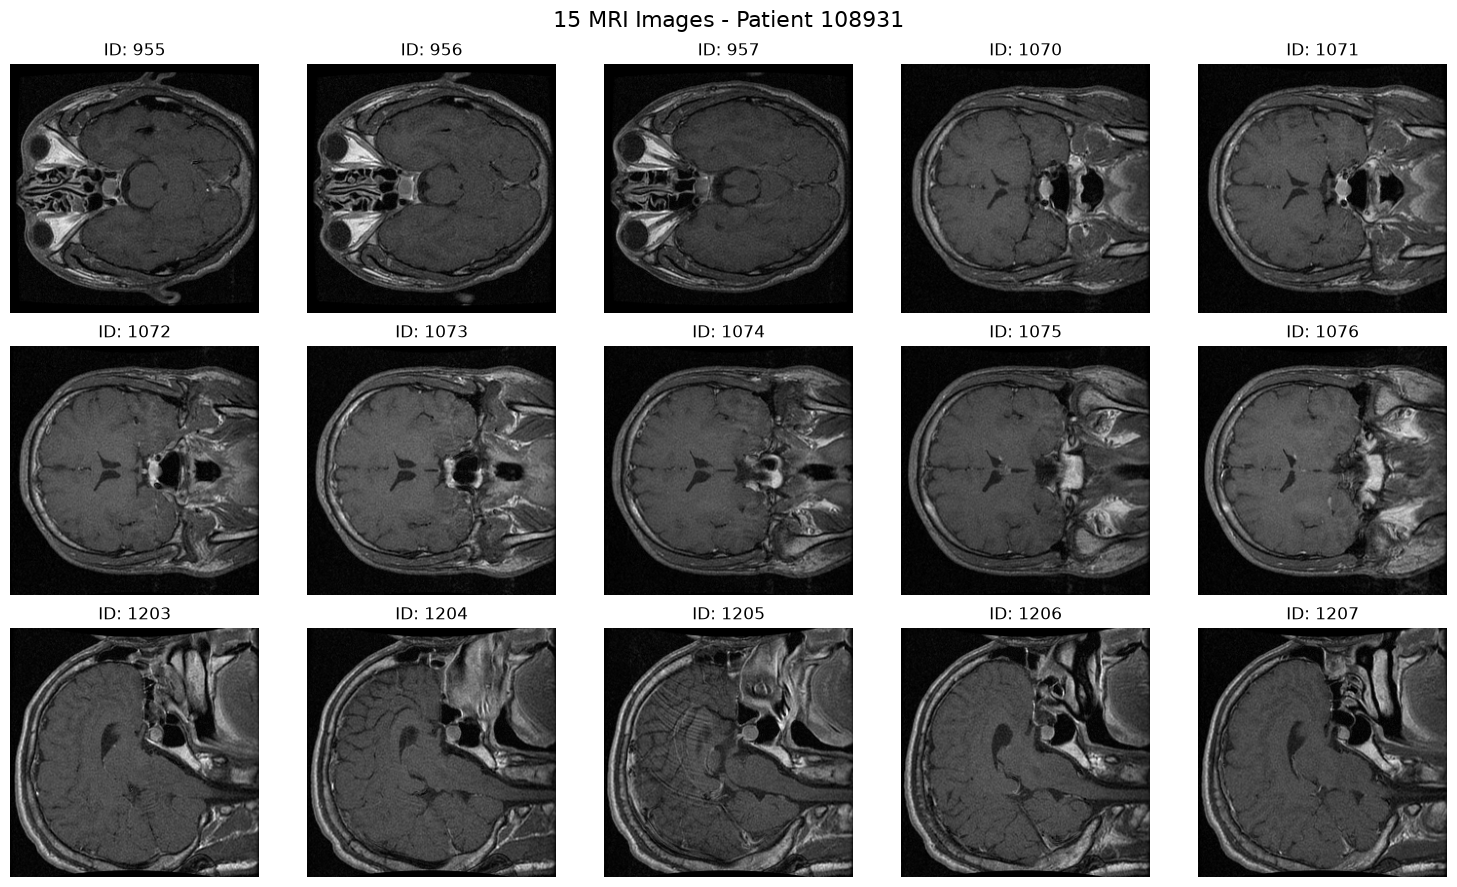

In [32]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for ax, record in zip(axes.flat, small_images):
    file = next(
        f for f in files
        if record["id"] in pq.read_table(
            f, columns=["id"]
        )["id"].to_pylist()
    )

    table = pq.read_table(
        file, columns=["id", "image"]
    )

    rows = table.to_pylist()
    image_record = next(
        row["image"]["bytes"]
        for row in rows
        if row["id"] == record["id"]
    )

    img = Image.open(BytesIO(image_record))

    ax.imshow(img, cmap="gray")
    ax.set_title(f"ID: {record['id']}")
    ax.axis("off")

plt.suptitle("15 MRI Images - Patient 108931", fontsize=16)
plt.tight_layout()
plt.show()

In [33]:
patient_images = []

for file in files:
    table = pq.read_table(
        file,
        columns=["id", "pid", "label_name", "image"]
    )

    for record in table.to_pylist():
        if record["pid"] == "108931":
            img = Image.open(BytesIO(record["image"]["bytes"]))

            patient_images.append({
                "id": record["id"],
                "label": record["label_name"],
                "size": img.size
            })

patient_108931_df = pd.DataFrame(patient_images)

print("Total images:", len(patient_108931_df))
print("\nImage dimensions:")
print(patient_108931_df["size"].value_counts())

print("\nPatient image records:")
display(patient_108931_df.sort_values("id"))

Total images: 15

Image dimensions:
size
(256, 256)    15
Name: count, dtype: int64

Patient image records:


,id,label,size
3,1070,pituitary,"(256, 256)"
4,1071,pituitary,"(256, 256)"
5,1072,pituitary,"(256, 256)"
6,1073,pituitary,"(256, 256)"
7,1074,pituitary,"(256, 256)"
8,1075,pituitary,"(256, 256)"
9,1076,pituitary,"(256, 256)"
10,1203,pituitary,"(256, 256)"
11,1204,pituitary,"(256, 256)"
12,1205,pituitary,"(256, 256)"


In [34]:
image_statistics = []

for file in files:
    table = pq.read_table(file, columns=["id", "pid", "image"])

    for record in table.to_pylist():
        img = Image.open(BytesIO(record["image"]["bytes"]))
        img_array = np.array(img)

        image_statistics.append({
            "id": record["id"],
            "pid": record["pid"],
            "width": img.width,
            "height": img.height,
            "min": img_array.min(),
            "max": img_array.max(),
            "mean": img_array.mean(),
            "std": img_array.std()
        })

image_stats_df = pd.DataFrame(image_statistics)

print("Pixel statistics grouped by image resolution:\n")

display(
    image_stats_df.groupby(["width", "height"])[
        ["min", "max", "mean", "std"]
    ].agg(["mean", "median", "min", "max"]).round(2)
)

Pixel statistics grouped by image resolution:



min                    max                        mean          \
             mean median min max    mean  median  min    max    mean  median   
width height                                                                   
256   256     0.0    0.0   0   0   267.6   264.0  238    305   56.99   57.71   
512   512     0.0    0.0   0   0  3405.5  2961.0  520  12728  469.40  480.07   

                                 std                          
                min      max    mean  median    min      max  
width height                                                  
256   256     44.89    71.83   39.90   40.06  34.89    49.21  
512   512     78.61  1238.03  525.86  493.19  72.06  1644.92

In [35]:
percentile_stats = []

for file in files:
    table = pq.read_table(file, columns=["id", "image"])

    for record in table.to_pylist():
        img = Image.open(BytesIO(record["image"]["bytes"]))
        img_array = np.array(img)

        percentile_stats.append({
            "id": record["id"],
            "width": img.width,
            "height": img.height,
            "p1": np.percentile(img_array, 1),
            "p50": np.percentile(img_array, 50),
            "p99": np.percentile(img_array, 99)
        })

percentile_df = pd.DataFrame(percentile_stats)

display(
    percentile_df.groupby(["width", "height"])[
        ["p1", "p50", "p99"]
    ].agg(["mean", "median", "min", "max"]).round(2)
)

p1                      p50                           p99  \
             mean median  min  max    mean median   min     max     mean   
width height                                                               
256   256     0.0    0.0  0.0  0.0   63.13   64.0  50.0    81.0   174.38   
512   512     0.0    0.0  0.0  0.0  242.82  148.0  14.0  1018.0  2110.78   

                                      
              median     min     max  
width height                          
256   256      166.0  155.00   210.0  
512   512     1970.0  269.57  6714.0

In [36]:
print("Median pixel intensity distribution by resolution:\n")

display(
    percentile_df.groupby(["width", "height"])["p50"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90])
    .round(2)
)

print("\n10 images with the lowest median intensity:")

display(
    percentile_df.nsmallest(10, "p50")[
        ["id", "width", "height", "p1", "p50", "p99"]
    ]
)

print("\n10 images with the highest median intensity:")

display(
    percentile_df.nlargest(10, "p50")[
        ["id", "width", "height", "p1", "p50", "p99"]
    ]
)

Median pixel intensity distribution by resolution:



,,count,mean,std,min,10%,25%,50%,75%,90%,max
width,height,,,,,,,,,,
256,256,15.0,63.13,8.13,50.0,51.2,60.0,64.0,67.0,69.8,81.0
512,512,3049.0,242.82,211.69,14.0,55.0,79.0,148.0,385.0,577.2,1018.0



10 images with the lowest median intensity:


,id,width,height,p1,p50,p99
86,585,512,512,0.0,14.0,760.0
1082,638,512,512,0.0,14.0,654.0
85,584,512,512,0.0,16.0,720.0
1081,637,512,512,0.0,16.0,657.0
991,532,512,512,0.0,17.0,549.0
1016,560,512,512,0.0,17.0,617.0
1067,619,512,512,0.0,17.0,551.0
1080,636,512,512,0.0,21.0,612.0
147,995,512,512,0.0,22.0,807.0
2289,2142,512,512,0.0,22.0,1332.0



10 images with the highest median intensity:


,id,width,height,p1,p50,p99
1777,1485,512,512,0.0,1018.0,2378.00
1778,1486,512,512,0.0,1012.0,2371.00
1775,1483,512,512,0.0,1008.0,2402.00
1776,1484,512,512,0.0,1004.0,2369.57
2826,2774,512,512,0.0,982.0,3322.00
2912,2877,512,512,0.0,981.0,2993.00
2828,2776,512,512,0.0,977.0,3084.00
2827,2775,512,512,0.0,961.0,3067.00
2855,2803,512,512,0.0,954.0,3300.00
2688,2608,512,512,0.0,948.0,3146.00


In [37]:
extreme_images = pd.concat([
    percentile_df.nsmallest(10, "p50"),
    percentile_df.nlargest(10, "p50")
]).drop_duplicates(subset="id")

extreme_metadata = metadata[
    metadata["id"].isin(extreme_images["id"])
][["id", "pid", "label_name", "fold"]]

extreme_analysis = extreme_images.merge(
    extreme_metadata,
    on="id",
    how="left"
)

display(
    extreme_analysis[
        ["id", "pid", "label_name", "fold",
         "width", "height", "p50", "p99"]
    ].sort_values("p50")
)

,id,pid,label_name,fold,width,height,p50,p99
0,585,110808,meningioma,1,512,512,14.0,760.00
1,638,113614,meningioma,4,512,512,14.0,654.00
2,584,110808,meningioma,1,512,512,16.0,720.00
3,637,113614,meningioma,4,512,512,16.0,657.00
4,532,106592,meningioma,4,512,512,17.0,549.00
5,560,107946,meningioma,2,512,512,17.0,617.00
6,619,112650,meningioma,3,512,512,17.0,551.00
7,636,113614,meningioma,4,512,512,21.0,612.00
8,995,112074,pituitary,1,512,512,22.0,807.00
9,2142,MR031409B,glioma,2,512,512,22.0,1332.00


In [38]:
image_patient_stats = percentile_df.merge(
    metadata[["id", "pid", "label_name", "fold"]],
    on="id",
    how="left"
)

patient_intensity_stats = (
    image_patient_stats
    .groupby(["pid", "label_name"])
    .agg(
        image_count=("p50", "count"),
        median_intensity=("p50", "median"),
        min_intensity=("p50", "min"),
        max_intensity=("p50", "max"),
        intensity_std=("p50", "std")
    )
    .reset_index()
)

print("Patient-level intensity variation:\n")

display(
    patient_intensity_stats.groupby("label_name")[
        ["median_intensity", "intensity_std"]
    ].describe().round(2)
)

print("\nPatients with the highest median intensity:")
display(
    patient_intensity_stats.nlargest(10, "median_intensity")
)

print("\nPatients with the lowest median intensity:")
display(
    patient_intensity_stats.nsmallest(10, "median_intensity")
)

Patient-level intensity variation:



median_intensity                                                \
                      count    mean     std   min     25%     50%     75%   
label_name                                                                  
glioma                 89.0  183.46  145.90  34.0   83.00  112.00  251.00   
meningioma             82.0  131.05  105.81  15.0   58.25   98.75  171.25   
pituitary              62.0  334.07  203.53  54.0  153.00  268.00  516.38   

                  intensity_std                                              \
              max         count    mean    std   min    25%     50%     75%   
label_name                                                                    
glioma      739.0          89.0  156.84  95.50  0.00  77.18  158.99  221.48   
meningioma  527.0          76.0  108.68  73.40  0.71  39.47  115.61  167.07   
pituitary   853.0          61.0   96.38  85.78  8.13  23.74   79.75  161.70   

                    
               max  
label_name          
glioma      415.06  
meningioma  237.06  
pituitary   398.84


Patients with the highest median intensity:


,pid,label_name,image_count,median_intensity,min_intensity,max_intensity,intensity_std
21,102648,pituitary,17,853.0,99.0,1018.0,398.842526
210,MR049942B,glioma,10,739.0,100.0,948.0,347.700078
44,104558,pituitary,24,719.5,396.0,851.0,124.532401
48,105187,pituitary,16,647.5,366.0,713.0,113.437722
154,98871,pituitary,20,621.5,368.0,697.0,89.119361
157,98992,pituitary,25,597.0,85.0,708.0,236.765355
68,107429,pituitary,20,590.5,197.0,678.5,148.056044
12,101145,pituitary,12,580.5,156.0,610.0,203.140621
125,114361,pituitary,10,578.0,124.0,679.0,237.068884
114,113274,pituitary,10,573.0,521.0,848.0,100.321982



Patients with the lowest median intensity:


,pid,label_name,image_count,median_intensity,min_intensity,max_intensity,intensity_std
91,110808,meningioma,2,15.0,14.0,16.0,1.414214
62,106592,meningioma,1,17.0,17.0,17.0,NaN
117,113614,meningioma,4,18.5,14.0,67.0,25.172737
137,95969,meningioma,1,22.0,22.0,22.0,NaN
110,112650,meningioma,2,26.5,17.0,36.0,13.435029
173,MR029209E,glioma,24,34.0,22.0,339.0,101.068494
181,MR034997,glioma,21,36.0,25.0,405.0,136.724036
46,104695,meningioma,3,37.0,36.0,42.0,3.214550
103,112062,meningioma,10,38.0,30.0,222.0,79.465506
66,107190,meningioma,4,39.5,36.0,230.0,95.855360


In [39]:
print("Intensity distribution across tumor classes:\n")

display(
    patient_intensity_stats.groupby("label_name").agg(
        patients=("pid", "nunique"),
        median_of_patient_medians=("median_intensity", "median"),
        minimum=("median_intensity", "min"),
        maximum=("median_intensity", "max"),
        average_within_patient_std=("intensity_std", "mean")
    ).round(2)
)

print("\n10 patients with the highest median intensity:")

display(
    patient_intensity_stats.nlargest(10, "median_intensity")
)

Intensity distribution across tumor classes:



,patients,median_of_patient_medians,minimum,maximum,average_within_patient_std
label_name,,,,,
glioma,89,112.00,34.0,739.0,156.84
meningioma,82,98.75,15.0,527.0,108.68
pituitary,62,268.00,54.0,853.0,96.38



10 patients with the highest median intensity:


,pid,label_name,image_count,median_intensity,min_intensity,max_intensity,intensity_std
21,102648,pituitary,17,853.0,99.0,1018.0,398.842526
210,MR049942B,glioma,10,739.0,100.0,948.0,347.700078
44,104558,pituitary,24,719.5,396.0,851.0,124.532401
48,105187,pituitary,16,647.5,366.0,713.0,113.437722
154,98871,pituitary,20,621.5,368.0,697.0,89.119361
157,98992,pituitary,25,597.0,85.0,708.0,236.765355
68,107429,pituitary,20,590.5,197.0,678.5,148.056044
12,101145,pituitary,12,580.5,156.0,610.0,203.140621
125,114361,pituitary,10,578.0,124.0,679.0,237.068884
114,113274,pituitary,10,573.0,521.0,848.0,100.321982


In [40]:
sample_patients = (
    patient_intensity_stats
    .groupby("label_name")["median_intensity"]
    .median()
)

print("Representative intensity values:")
display(sample_patients)

Representative intensity values:


label_name
glioma        112.00
meningioma     98.75
pituitary     268.00
Name: median_intensity, dtype: float64

In [41]:
representative_patients = []

for tumor_class, target_intensity in sample_patients.items():

    class_patients = patient_intensity_stats[
        patient_intensity_stats["label_name"] == tumor_class
    ].copy()

    class_patients["intensity_difference"] = (
        class_patients["median_intensity"] - target_intensity
    ).abs()

    representative = class_patients.sort_values(
        "intensity_difference"
    ).iloc[0]

    representative_patients.append(representative)

representative_patients_df = pd.DataFrame(
    representative_patients
)

display(
    representative_patients_df[
        ["pid", "label_name", "image_count",
         "median_intensity", "min_intensity", "max_intensity"]
    ]
)

,pid,label_name,image_count,median_intensity,min_intensity,max_intensity
14,101384,glioma,3,112.0,62.0,157.0
82,109350,meningioma,2,95.5,95.0,96.0
7,101017,pituitary,15,244.0,224.0,292.0


In [42]:
representative_ids = set(
    representative_patients_df["pid"].astype(str)
)

representative_images = {}

for file in files:
    table = pq.read_table(
        file,
        columns=["pid", "id", "label_name", "image"]
    )

    for record in table.to_pylist():
        if str(record["pid"]) in representative_ids:

            representative_images.setdefault(
                str(record["pid"]), []
            ).append({
                "id": record["id"],
                "label": record["label_name"],
                "image": record["image"]["bytes"]
            })

for pid, images in representative_images.items():
    print(f"Patient {pid}: {len(images)} images")

Patient 101384: 3 images
Patient 109350: 2 images
Patient 101017: 15 images


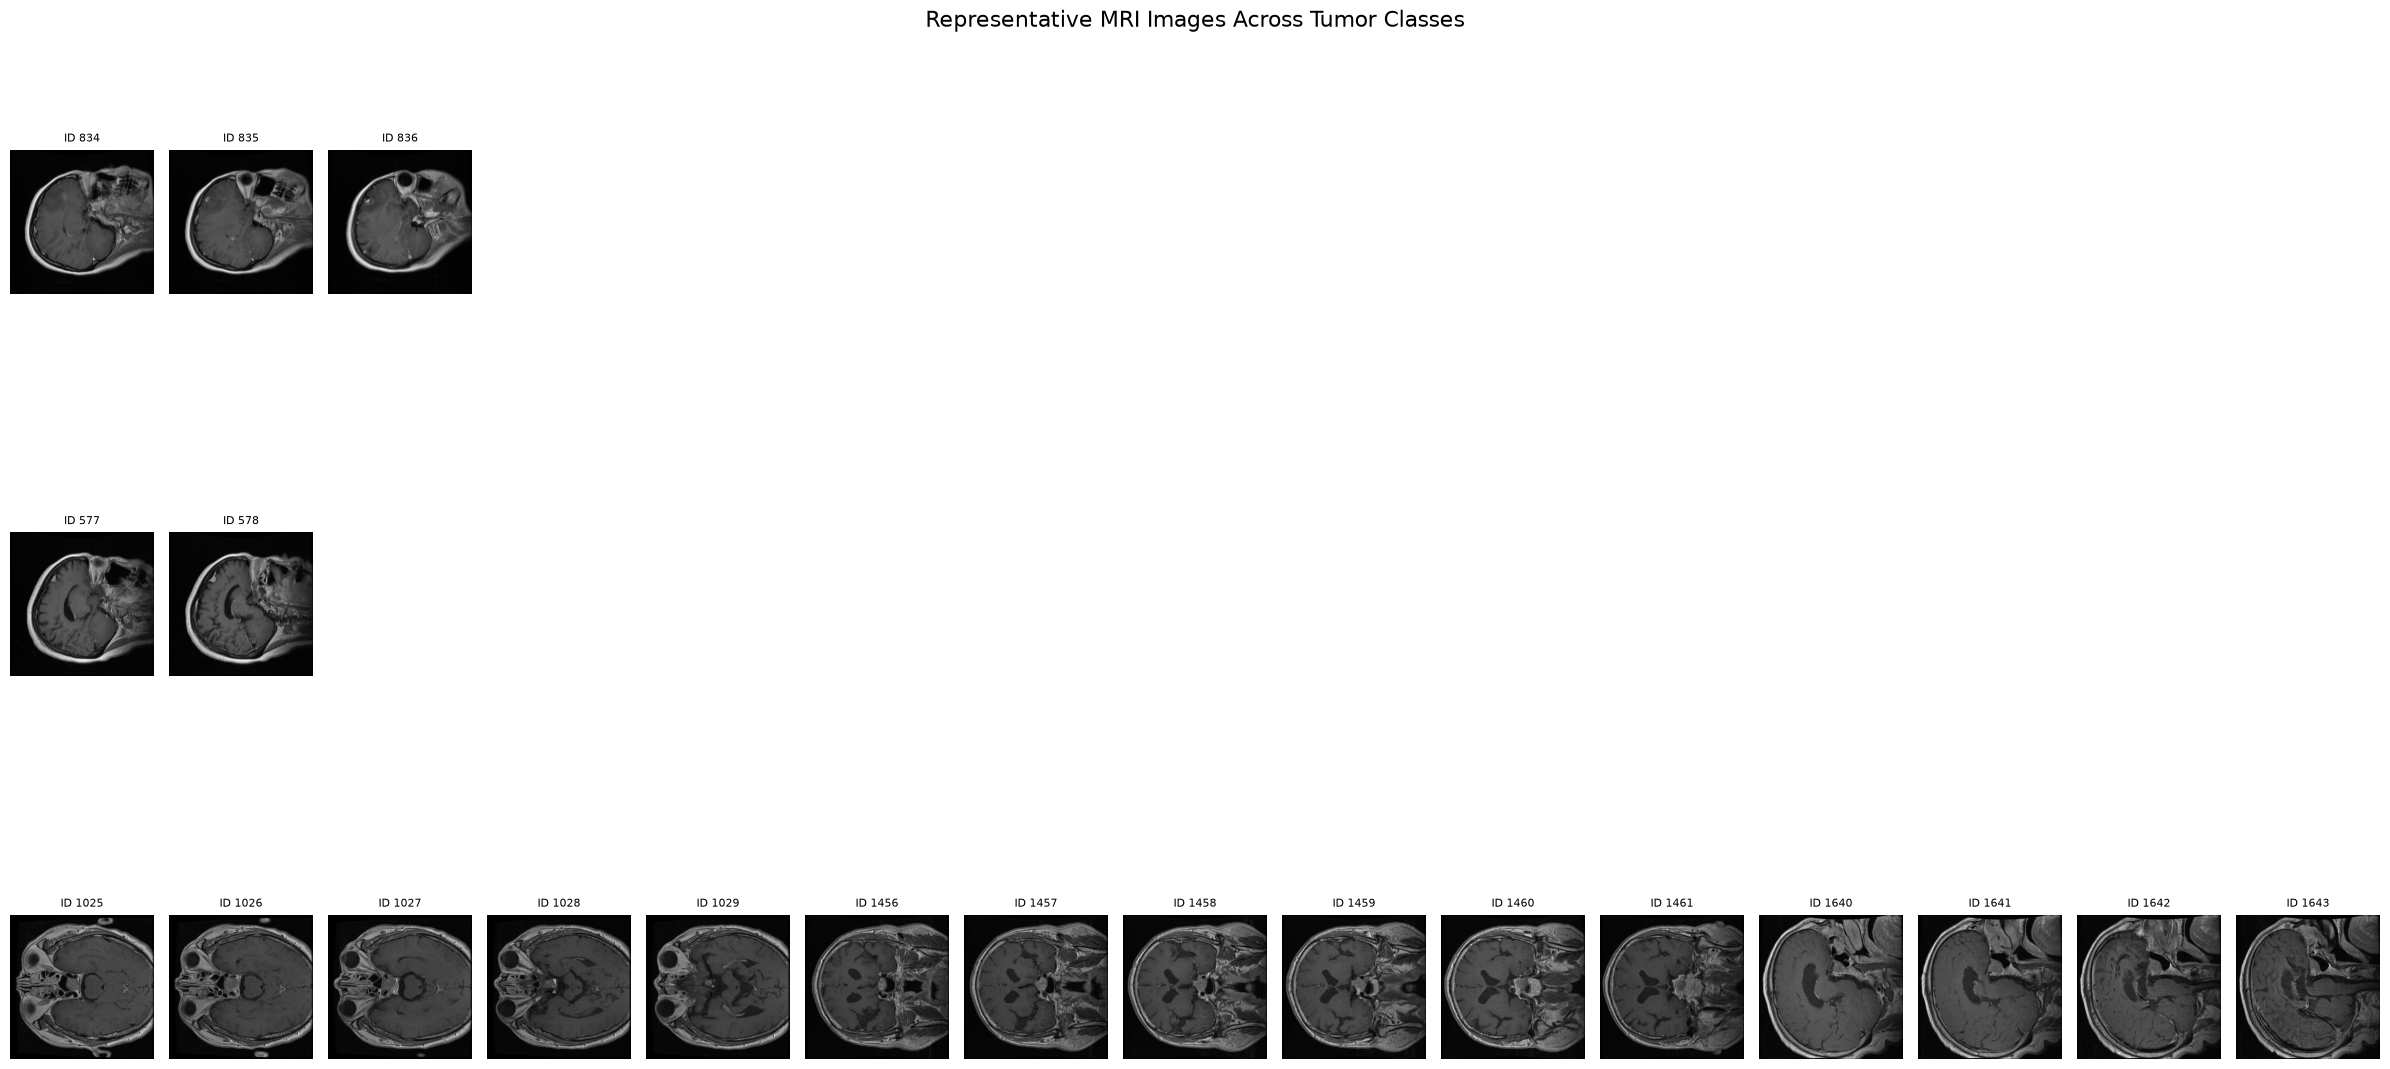

In [43]:
fig, axes = plt.subplots(3, 15, figsize=(24, 12))

patient_order = [
    ("101384", "Glioma"),
    ("109350", "Meningioma"),
    ("101017", "Pituitary")
]

for row, (pid, label) in enumerate(patient_order):

    images = representative_images[pid]

    for col in range(15):
        ax = axes[row, col]

        if col < len(images):
            img = Image.open(BytesIO(images[col]["image"]))
            ax.imshow(img, cmap="gray")
            ax.set_title(f"ID {images[col]['id']}", fontsize=8)
        else:
            ax.axis("off")
            continue

        ax.axis("off")

    axes[row, 0].set_ylabel(
        label,
        fontsize=12,
        rotation=0,
        labelpad=45
    )

plt.suptitle(
    "Representative MRI Images Across Tumor Classes",
    fontsize=16
)

plt.tight_layout()
plt.show()

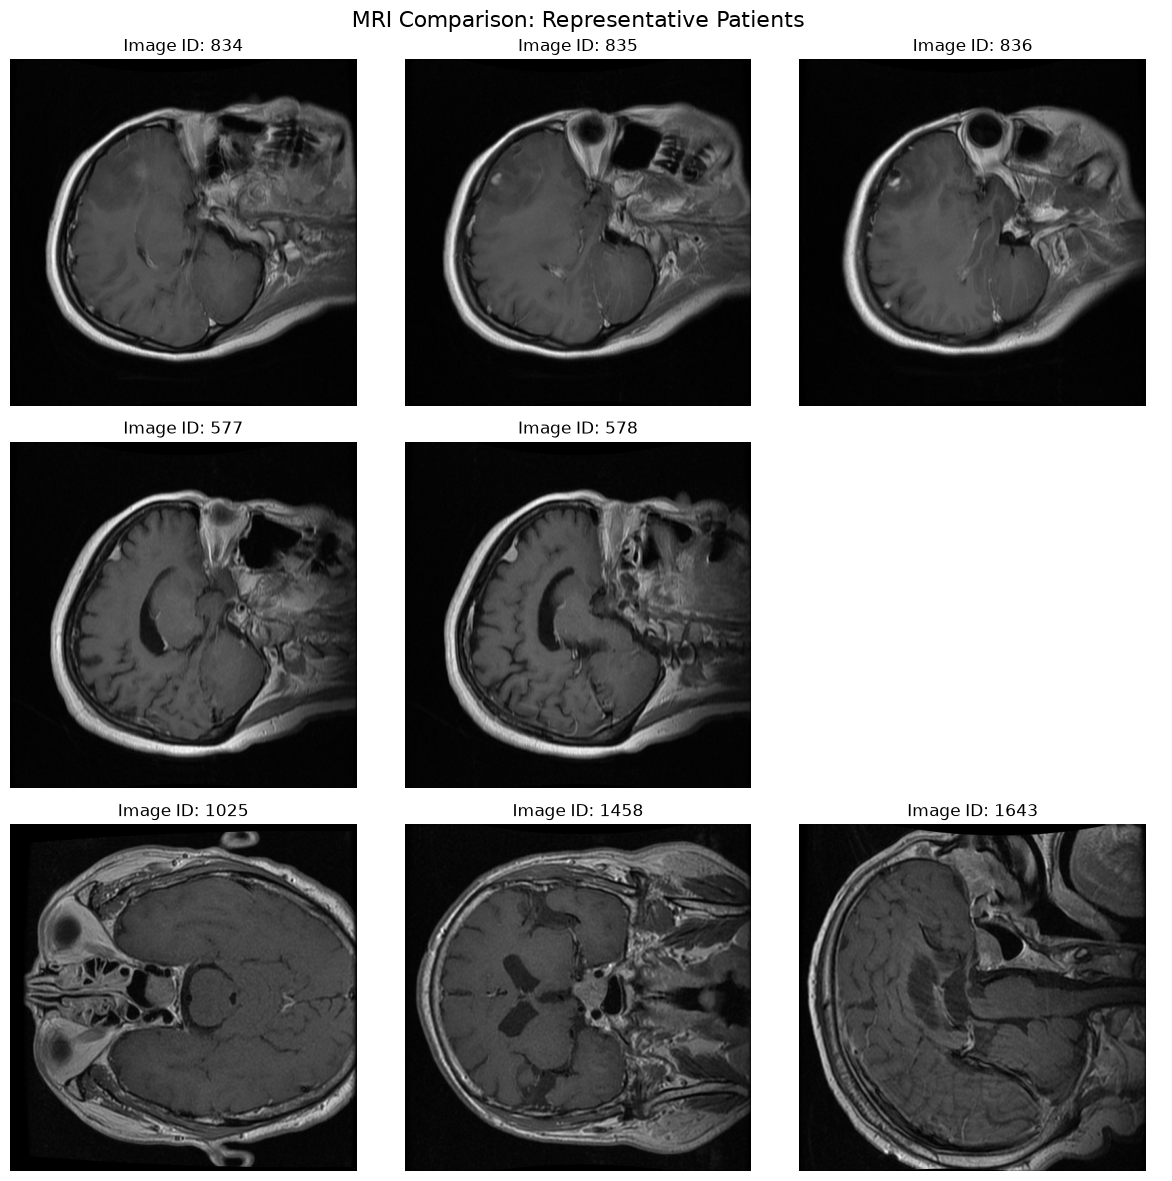

In [44]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

patient_order = [
    ("101384", "Glioma"),
    ("109350", "Meningioma"),
    ("101017", "Pituitary")
]

for row, (pid, label) in enumerate(patient_order):

    images = representative_images[pid]

    selected_indices = np.linspace(
        0, len(images) - 1,
        min(3, len(images)),
        dtype=int
    )

    for col in range(3):
        ax = axes[row, col]

        if col < len(selected_indices):
            record = images[selected_indices[col]]
            img = Image.open(BytesIO(record["image"]))

            ax.imshow(img, cmap="gray")
            ax.set_title(f"Image ID: {record['id']}")
        else:
            ax.axis("off")
            continue

        ax.axis("off")

    axes[row, 0].set_ylabel(
        label,
        fontsize=12,
        rotation=0,
        labelpad=55
    )

plt.suptitle(
    "MRI Comparison: Representative Patients",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [45]:
orientation_stats = []

for file in files:
    table = pq.read_table(file, columns=["id", "pid", "image"])

    for record in table.to_pylist():
        img = Image.open(BytesIO(record["image"]["bytes"]))

        orientation_stats.append({
            "id": record["id"],
            "pid": record["pid"],
            "size": img.size,
            "mode": img.mode,
            "info_keys": list(img.info.keys())
        })

orientation_df = pd.DataFrame(orientation_stats)

print("Image modes:")
print(orientation_df["mode"].value_counts())

print("\nImage dimensions:")
print(orientation_df["size"].value_counts())

print("\nPNG metadata keys:")
print(
    orientation_df["info_keys"]
    .explode()
    .value_counts()
)

Image modes:
mode
I;16    3064
Name: count, dtype: int64

Image dimensions:
size
(512, 512)    3049
(256, 256)      15
Name: count, dtype: int64

PNG metadata keys:
Series([], Name: count, dtype: int64)


In [46]:
quality_stats = image_stats_df[
    ["id", "pid", "mean", "std", "max"]
].copy()

print("Images with the lowest pixel variation:")

display(
    quality_stats.nsmallest(15, "std")
)

print("\nImages with the lowest mean intensity:")

display(
    quality_stats.nsmallest(15, "mean")
)

Images with the lowest pixel variation:


,id,pid,mean,std,max
1546,1204,108931,57.714859,34.894822,242
1548,1206,108931,56.330322,35.619406,241
1545,1203,108931,59.321564,35.636936,238
1547,1205,108931,58.845642,36.776449,246
1549,1207,108931,60.753204,37.608531,261
1352,957,108931,44.886505,38.236961,284
1351,956,108931,46.614395,39.943733,259
1350,955,108931,46.149078,40.064017,264
1440,1072,108931,57.298492,40.479702,267
1438,1070,108931,54.982880,40.600471,281



Images with the lowest mean intensity:


,id,pid,mean,std,max
1352,957,108931,44.886505,38.236961,284
1350,955,108931,46.149078,40.064017,264
1351,956,108931,46.614395,39.943733,259
1438,1070,108931,54.982880,40.600471,281
1548,1206,108931,56.330322,35.619406,241
1440,1072,108931,57.298492,40.479702,267
1439,1071,108931,57.443115,41.240795,277
1546,1204,108931,57.714859,34.894822,242
1547,1205,108931,58.845642,36.776449,246
1441,1073,108931,59.052567,41.152288,256


In [47]:
import hashlib

image_hashes = []

for file in files:
    table = pq.read_table(file, columns=["id", "pid", "image"])

    for record in table.to_pylist():
        image_bytes = record["image"]["bytes"]

        image_hashes.append({
            "id": record["id"],
            "pid": record["pid"],
            "hash": hashlib.sha256(image_bytes).hexdigest()
        })

hash_df = pd.DataFrame(image_hashes)

duplicate_images = hash_df[
    hash_df.duplicated(subset="hash", keep=False)
].sort_values("hash")

print("Total images:", len(hash_df))
print("Unique image contents:", hash_df["hash"].nunique())
print("Duplicate image records:", len(duplicate_images))

display(duplicate_images)

Total images: 3064
Unique image contents: 3064
Duplicate image records: 0


,id,pid,hash


In [48]:
print("Total image records:", len(metadata))

print(
    "Unique image IDs:",
    metadata["id"].nunique()
)

print(
    "Duplicate image IDs:",
    metadata["id"].duplicated().sum()
)

print(
    "Missing patient IDs:",
    metadata["pid"].isna().sum()
)

print(
    "Images without a patient association:",
    metadata["pid"].isna().sum()
)

Total image records: 3064
Unique image IDs: 3064
Duplicate image IDs: 0
Missing patient IDs: 0
Images without a patient association: 0


In [49]:
aspect_ratios = []

for file in files:
    table = pq.read_table(file, columns=["id", "pid", "image"])

    for record in table.to_pylist():
        img = Image.open(BytesIO(record["image"]["bytes"]))

        width, height = img.size

        aspect_ratios.append({
            "id": record["id"],
            "pid": record["pid"],
            "width": width,
            "height": height,
            "aspect_ratio": round(width / height, 3)
        })

aspect_df = pd.DataFrame(aspect_ratios)

print("Aspect ratio distribution:")
display(aspect_df["aspect_ratio"].value_counts())

print("\nUnique image dimensions:")
display(
    aspect_df.groupby(["width", "height"])
    .size()
    .reset_index(name="image_count")
)

print("\nNon-square images:")
display(
    aspect_df[aspect_df["aspect_ratio"] != 1.0]
)

Aspect ratio distribution:


aspect_ratio
1.0    3064
Name: count, dtype: int64


Unique image dimensions:


,width,height,image_count
0,256,256,15
1,512,512,3049



Non-square images:


,id,pid,width,height,aspect_ratio


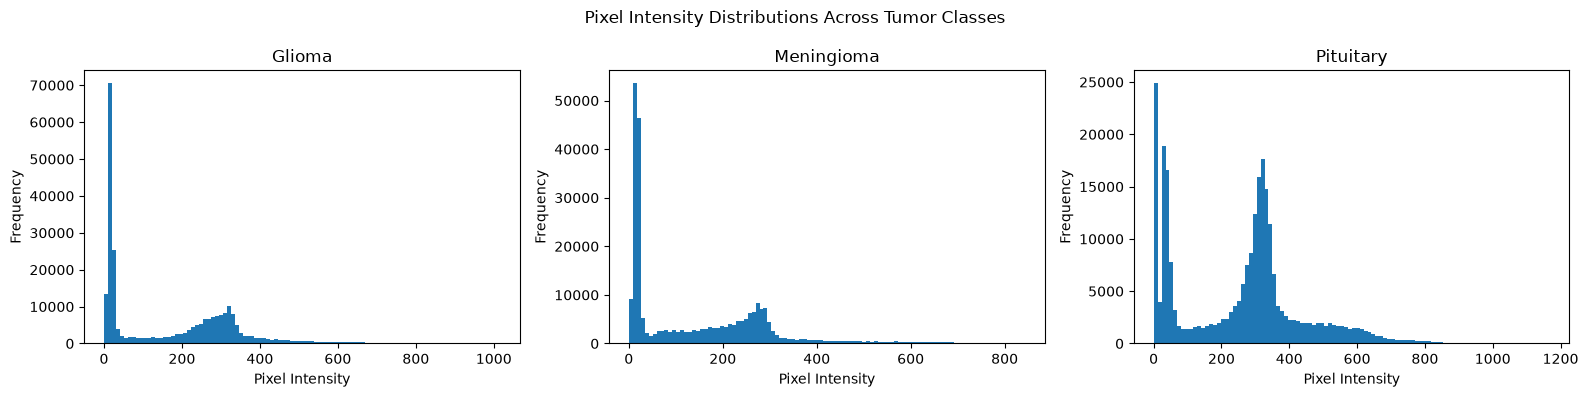

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (_, patient) in zip(
    axes,
    representative_patients_df.iterrows()
):
    pid = str(patient["pid"])
    record = representative_images[pid][0]

    img = Image.open(BytesIO(record["image"]))
    img_array = np.array(img)

    ax.hist(
        img_array.flatten(),
        bins=100
    )

    ax.set_title(patient["label_name"].capitalize())
    ax.set_xlabel("Pixel Intensity")
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Pixel Intensity Distributions Across Tumor Classes"
)

plt.tight_layout()
plt.show()

In [52]:
training_pixel_samples = []

rng = np.random.default_rng(42)

for file in train_files:
    table = pq.read_table(file, columns=["image"])

    for record in table.to_pylist():
        img = Image.open(BytesIO(record["image"]["bytes"]))
        img_array = np.asarray(img, dtype=np.float32)

        pixels = img_array.flatten()

        sample_size = min(10000, len(pixels))

        sampled_pixels = rng.choice(
            pixels,
            size=sample_size,
            replace=False
        )

        training_pixel_samples.append(sampled_pixels)

all_training_pixels = np.concatenate(training_pixel_samples)

print("Sampled training pixel statistics:\n")

print("Total sampled pixels:", len(all_training_pixels))
print("Minimum:", np.min(all_training_pixels))
print("Maximum:", np.max(all_training_pixels))
print("Mean:", np.mean(all_training_pixels))
print("Standard deviation:", np.std(all_training_pixels))

print("\nPercentiles:")

for p in [1, 5, 25, 50, 75, 95, 99, 99.9]:
    print(f"{p}th percentile:", np.percentile(all_training_pixels, p))

Sampled training pixel statistics:

Total sampled pixels: 25220000
Minimum: 0.0
Maximum: 10892.0
Mean: 457.96317
Standard deviation: 633.8943

Percentiles:
1th percentile: 0.0
5th percentile: 0.0
25th percentile: 31.0
50th percentile: 155.0
75th percentile: 736.0
95th percentile: 1689.0
99th percentile: 2706.0
99.9th percentile: 4718.0
